In [5]:
!pip install langchain langchain_core langgraph -qqq

### **Iterative Workflow undestanding using tweet generator and evaluator**

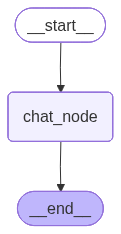

In [2]:
!pip install langchain_openai -qqq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.9/84.9 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 496.3/496.3 kB 7.8 MB/s eta 0:00:00


In [15]:
from langgraph.graph import StateGraph,START,END
from pydantic import BaseModel,Field
from typing import TypedDict,Annotated,Literal
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage,BaseMessage
from langgraph.checkpoint.memory import MemorySaver

In [8]:
import os
from google.colab import userdata
os.environ['OPENAI_API_KEY']=userdata.get('OPENAI_API_KEY')

In [9]:
llm=ChatOpenAI(model='gpt-5-nano')

In [10]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
  messages: Annotated[list[BaseMessage],add_messages]

In [11]:
def chat_node(state:ChatState):
  msg=state['messages']
  response=llm.invoke(msg).content

  return {'messages':[response]}

In [20]:
checkpointer=MemorySaver()
#make graph
graph=StateGraph(ChatState)

#make nodes
graph.add_node('chat_node',chat_node)

#make edges
graph.add_edge(START,'chat_node')
graph.add_edge('chat_node',END)

#compile graph
workflow=graph.compile(checkpointer=checkpointer)

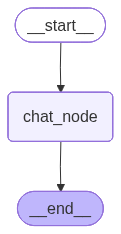

In [21]:
workflow

In [16]:
##before implementing checkpointer

In [17]:
inital_state={
    'messages':[HumanMessage(content="My name is Pankaj")]
}
res=workflow.invoke(inital_state)['messages'][-1].content
print(res)

Nice to meet you, Pankaj! How can I help you today? If you’d like, I can address you as Pankaj during this chat. What would you like to work on—writing, coding, learning something new, planning something, or something else?


In [18]:
inital_state={
    'messages':[HumanMessage(content="what my name is ?")]
}
res=workflow.invoke(inital_state)['messages'][-1].content
print(res)

I don’t know your name unless you tell me. If you share a name or a nickname you’d like me to use, I’ll address you that way for this chat. Would you like to tell me how you’d like to be called?


In [19]:
#after implementauon of checkpointer

In [23]:
thread_id=1
config={"configurable":{'thread_id':thread_id}}

In [26]:
inital_state={
    'messages':[HumanMessage(content="My name is Pankaj")]
}
res=workflow.invoke(inital_state,config=config)['messages'][-1].content
print(res)

Nice to meet you, Pankaj! How can I help you today? I can assist with writing, explanations, coding, planning, studying, or just chat. If you’d like, I can address you as Pankaj throughout this chat. What would you like to do?


In [27]:
inital_state={
    'messages':[HumanMessage(content="what my name is ?")]
}
res=workflow.invoke(inital_state,config=config)['messages'][-1].content
print(res)

Your name is Pankaj.

Would you like me to address you as Pankaj throughout our chat? What would you like to do today, Pankaj?


In [28]:
workflow.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='My name is Pankaj', additional_kwargs={}, response_metadata={}, id='09371ffe-a8a9-4831-b6c8-69e3d4d80001'), HumanMessage(content='Nice to meet you, Pankaj! How can I help you today? I can assist with writing, explanations, coding, planning, studying, or just chat. If you’d like, I can address you as Pankaj throughout this chat. What would you like to do?', additional_kwargs={}, response_metadata={}, id='ba4fd278-0a75-4d7f-85cc-cfa730df4aec'), HumanMessage(content='what my name is ?', additional_kwargs={}, response_metadata={}, id='56e03cf5-1a9a-4110-ad20-e32c712b8468'), HumanMessage(content='Your name is Pankaj.\n\nWould you like me to address you as Pankaj throughout our chat? What would you like to do today, Pankaj?', additional_kwargs={}, response_metadata={}, id='320069e4-fbcd-423d-9f98-412bc547b184')]}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f10650b-76f8-6626-8004-f065782b